<a href="https://colab.research.google.com/github/YashPrakash1212/MATLAB_SUMMER_PROJECTS/blob/main/Final_Project_of_Stock_Prediction_with_Taylor_Polynomials.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter a stock ticker (e.g. AAPL, MSFT, TSLA): MSFT

Fetching price history for MSFT...

Centering Taylor expansion at 2026-08-14 (price = $494.47)
Estimated derivatives (finite differences):
  f^(1)(t0) ≈ -1.4772
  f^(2)(t0) ≈ -5.9189
  f^(3)(t0) ≈ -21.7191
  f^(4)(t0) ≈ -46.6322


/tmp/ipykernel_2860/4068913101.py:24: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, period=period, progress=False)



Saved plot to MSFT_taylor_approximation.png

Mean absolute error by degree over the held-out window:
  Degree 1: MAE = $11.177
  Degree 2: MAE = $109.005
  Degree 3: MAE = $1103.808
  Degree 4: MAE = $5578.206
Saved error chart to MSFT_error_by_degree.png


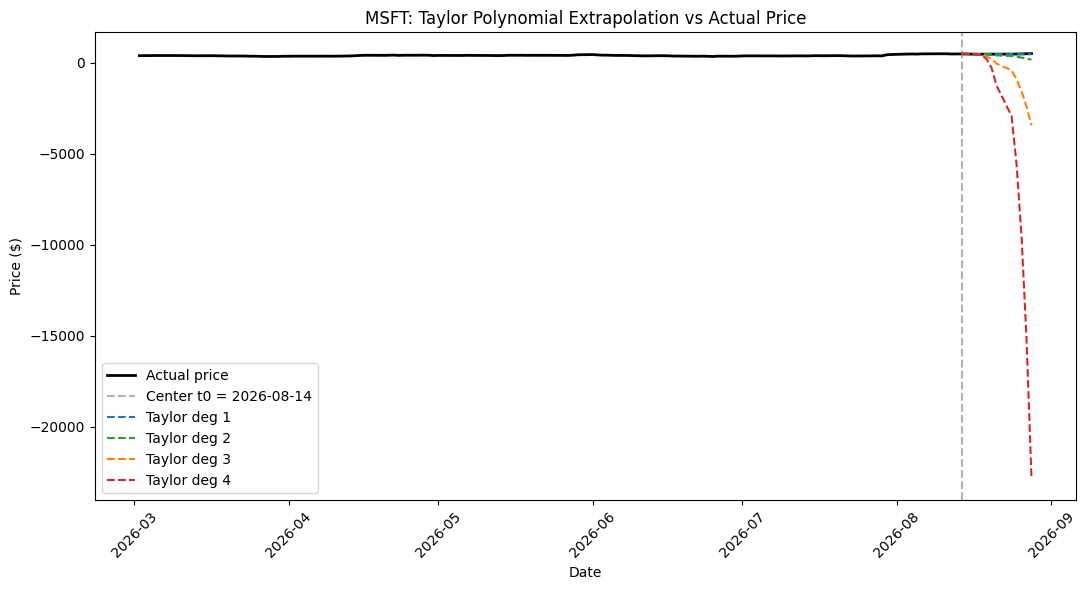

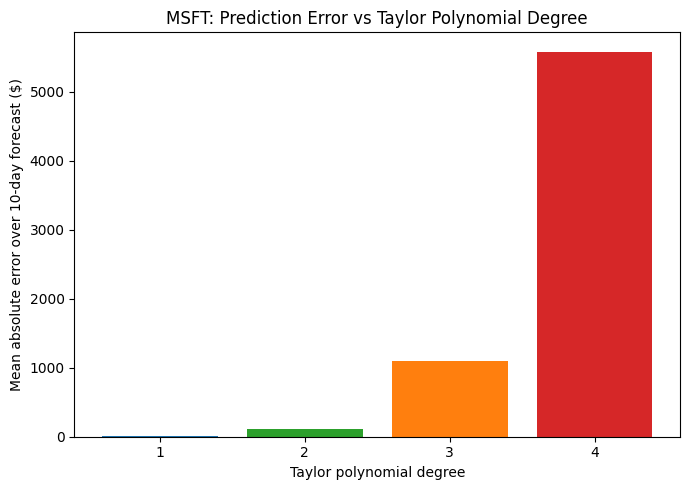

In [ ]:
"""
Taylor Series Stock Approximator
---------------------------------
AP Calculus BC project: build Taylor polynomials centered at a "today" point
using finite-difference-estimated derivatives, then see how well they predict
a real stock's future price -- a hands-on look at Taylor approximation error
and why it grows the farther you extrapolate from the center.

Requirements:
    pip install yfinance numpy matplotlib

Run:
    python taylor_stock_approximator.py
"""

import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime


def get_price_history(ticker, period="6mo"):
    """Download daily closing prices for a ticker."""
    data = yf.download(ticker, period=period, progress=False)
    if data.empty:
        raise ValueError(f"No data found for ticker '{ticker}'. Check the symbol and try again.")
    close = data["Close"]
    if isinstance(close, np.ndarray) is False and hasattr(close, "squeeze"):
        close = close.squeeze()
    return close.dropna()


def estimate_derivatives(y, t0_index, h=1, max_order=4):
    """
    Estimate f'(t0), f''(t0), f'''(t0), f''''(t0) using centered/backward
    finite difference formulas, since we only have data up to t0 (no future
    info allowed -- that would defeat the point of "predicting" forward).

    y: array of prices (evenly spaced by trading day)
    t0_index: index in y treated as the center t0 ("today")
    h: step size (1 trading day)
    """
    derivs = {}

    def f(k):
        return y[t0_index - k]

    derivs[1] = (f(0) - f(1)) / h

    derivs[2] = (f(0) - 2 * f(1) + f(2)) / h**2

    derivs[3] = (f(0) - 3 * f(1) + 3 * f(2) - f(3)) / h**3

    derivs[4] = (f(0) - 4 * f(1) + 6 * f(2) - 4 * f(3) + f(4)) / h**4

    return {k: v for k, v in derivs.items() if k <= max_order}


def taylor_polynomial(t, t0, f0, derivs, degree):
    """
    Evaluate the degree-n Taylor polynomial centered at t0:
        P_n(t) = f(t0) + f'(t0)(t-t0) + f''(t0)/2! (t-t0)^2 + ...
    t can be a scalar or numpy array.
    """
    dt = t - t0
    result = np.full_like(dt, f0, dtype=float)
    factorial = 1
    for n in range(1, degree + 1):
        factorial *= n
        result += derivs[n] * dt**n / factorial
    return result


def main():
    ticker = input("Enter a stock ticker (e.g. AAPL, MSFT, TSLA): ").strip().upper()

    print(f"\nFetching price history for {ticker}...")
    prices = get_price_history(ticker, period="6mo")
    y = prices.values
    dates = prices.index
    n = len(y)

    HOLD_OUT = 10
    t0_index = n - HOLD_OUT - 1

    if t0_index < 5:
        raise ValueError("Not enough data to estimate derivatives. Try a longer period.")

    t0 = t0_index
    f0 = y[t0_index]

    derivs = estimate_derivatives(y, t0_index, h=1, max_order=4)

    print(f"\nCentering Taylor expansion at {dates[t0_index].date()} "
          f"(price = ${f0:.2f})")
    print("Estimated derivatives (finite differences):")
    for order, val in derivs.items():
        print(f"  f^({order})(t0) ≈ {val:.4f}")

    t_full = np.arange(n)
    t_future = np.arange(t0_index, n)

    degrees = [1, 2, 3, 4]
    predictions = {}
    for deg in degrees:
        predictions[deg] = taylor_polynomial(t_future, t0, f0, derivs, deg)

    plt.figure(figsize=(11, 6))
    plt.plot(dates, y, label="Actual price", color="black", linewidth=2)
    plt.axvline(dates[t0_index], color="gray", linestyle="--", alpha=0.6,
                label=f"Center t0 = {dates[t0_index].date()}")

    colors = ["tab:blue", "tab:green", "tab:orange", "tab:red"]
    for deg, color in zip(degrees, colors):
        plt.plot(dates[t_future], predictions[deg],
                  label=f"Taylor deg {deg}", color=color, linestyle="--")

    plt.title(f"{ticker}: Taylor Polynomial Extrapolation vs Actual Price")
    plt.xlabel("Date")
    plt.ylabel("Price ($)")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    out_path = f"{ticker}_taylor_approximation.png"
    plt.savefig(out_path, dpi=150)
    print(f"\nSaved plot to {out_path}")

    actual_future = y[t0_index:]
    print("\nMean absolute error by degree over the held-out window:")
    errors = {}
    for deg in degrees:
        err = np.mean(np.abs(predictions[deg] - actual_future))
        errors[deg] = err
        print(f"  Degree {deg}: MAE = ${err:.3f}")

    plt.figure(figsize=(7, 5))
    plt.bar([str(d) for d in degrees], [errors[d] for d in degrees],
            color=colors)
    plt.title(f"{ticker}: Prediction Error vs Taylor Polynomial Degree")
    plt.xlabel("Taylor polynomial degree")
    plt.ylabel(f"Mean absolute error over {HOLD_OUT}-day forecast ($)")
    plt.tight_layout()
    err_path = f"{ticker}_error_by_degree.png"
    plt.savefig(err_path, dpi=150)
    print(f"Saved error chart to {err_path}")

    plt.show()


if __name__ == "__main__":
    main()